# 6. Final Full-Data Training

Retrain the best-performing Population Trajectories Random Forest on every labeled trial to squeeze out the last bit of accuracy before submitting to Kaggle.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

pd.options.display.float_format = '{:,.4f}'.format
DATA_DIR = Path('../data/raw')
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')

feature_drop = ['session_id', 'trial_number', 'TRIAL_TYPE']
X = train.drop(columns=feature_drop)
y = train['TRIAL_TYPE']
X_test = test.drop(columns=['session_id', 'trial_number'])

def get_population_dynamics(df: pd.DataFrame) -> pd.DataFrame:
    time_cols = [c for c in df.columns if '_time_' in c]
    time_map = {}
    for col in time_cols:
        try:
            idx = int(col.split('_time_')[1])
        except ValueError:
            continue
        time_map.setdefault(idx, []).append(col)

    feature_blocks = []
    for t in sorted(time_map.keys()):
        cols = time_map[t]
        values = df[cols].values
        block = pd.DataFrame({
            f'pop_mean_t{t}': values.mean(axis=1),
            f'pop_max_t{t}': values.max(axis=1),
            f'pop_std_t{t}': values.std(axis=1),
            f'pop_sparsity_t{t}': (values > 0).mean(axis=1)
        }, index=df.index)
        feature_blocks.append(block)

    return pd.concat(feature_blocks, axis=1)

X_pop_all = get_population_dynamics(X).fillna(0)
X_test_pop = get_population_dynamics(X_test).fillna(0)

le = LabelEncoder()
y_encoded = le.fit_transform(y)

rf_pop_final = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=4,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_pop_final.fit(X_pop_all, y_encoded)
print('Finished training Population Trajectories RF on the full dataset.')

Finished training Population Trajectories RF on the full dataset.


# 7. Feature Importance Analysis

Identify the most informative population statistics and time bins to understand the biological story behind the classifier.

,importance
pop_sparsity_t20,0.0516
pop_sparsity_t10,0.0480
pop_sparsity_t12,0.0360
pop_sparsity_t27,0.0358
pop_sparsity_t19,0.0354
pop_sparsity_t22,0.0354
pop_sparsity_t1,0.0353
pop_sparsity_t17,0.0353
pop_sparsity_t9,0.0348
pop_sparsity_t2,0.0345


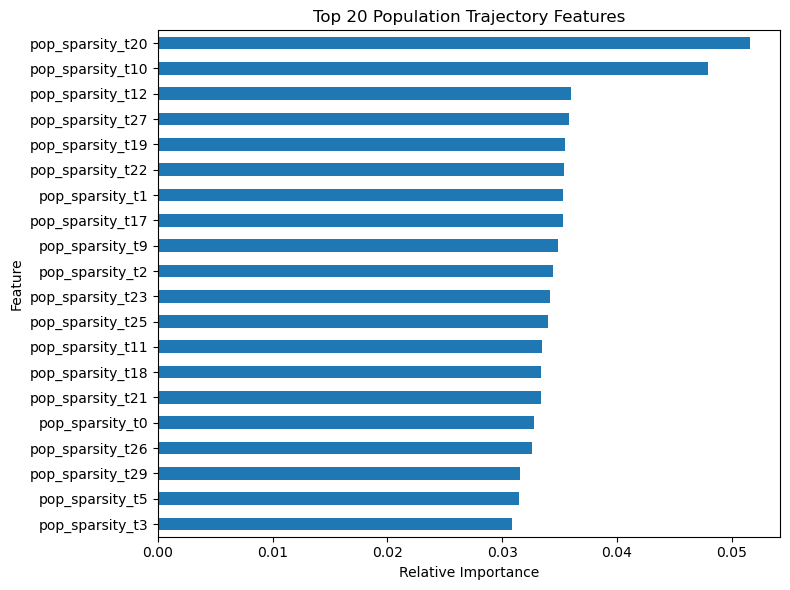

In [2]:
importances = pd.Series(rf_pop_final.feature_importances_, index=X_pop_all.columns)
top20 = importances.sort_values(ascending=False).head(20)

display(top20.to_frame('importance'))

ax = top20.sort_values().plot(kind='barh', figsize=(8, 6), color='#1f77b4')
ax.set_xlabel('Relative Importance')
ax.set_ylabel('Feature')
ax.set_title('Top 20 Population Trajectory Features')
plt.tight_layout()
plt.show()

# 8. Generate Final Submission

Score every test trial with the fully trained model, decode the predictions, and save the CSV for Kaggle upload.

In [3]:
test_preds = rf_pop_final.predict(X_test_pop)
final_labels = le.inverse_transform(test_preds)
submission = pd.DataFrame({
    'ID': np.arange(1, len(final_labels) + 1),
    'TRIAL_TYPE': final_labels
})
output_path = Path('final_population_rf_submission.csv')
submission.to_csv(output_path, index=False)
print(f'Saved submission to {output_path.resolve()}')

Saved submission to C:\Users\akh17\Desktop\EPFL\Biological-data-science-II\notebooks\final_population_rf_submission.csv
